In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"C:\Users\LENOVO\Downloads\ecommerce_sales_raw.csv")

In [3]:
df.head()

,Row_ID,Order_ID,Order_Date,Ship_Date,Ship_Mode,Customer_ID,Customer_Name,Segment,Country,City,...,Postal_Code,Region,Product_ID,Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit
0,1,ORD-12233,2024-04-14,2024-04-20,Standard Class,CUST-0143,Customer 0143,Home Office,United States,Los Angeles,...,90001.0,West,PROD-532,Office Supplies,Paper,Copy Paper,13.30,1,0.30,0.34
1,2,ORD-12932,2024-01-28,2024-02-02,Same Day,CUST-0617,Customer 0617,Consumer,United States,Los Angeles,...,90001.0,West,PROD-559,Technology,Phones,Wireless Headphones,1793.30,7,0.05,48.92
2,3,ORD-10881,2024-12-14,2024-12-17,First Class,CUST-0433,Customer 0433,Consumer,United States,Chicago,...,60601.0,Central,PROD-194,Office Supplies,Paper,Sticky Notes,132.19,5,0.05,22.81
3,4,ORD-12196,2024-02-14,2024-02-20,Standard Class,CUST-0271,Customer 0271,Corporate,United States,Miami,...,33101.0,South,PROD-180,Technology,Accessories,Wireless Mouse,1429.11,8,0.15,52.99
4,5,ORD-12708,2025-12-22,2025-12-23,Second Class,CUST-0197,Customer 0197,Corporate,United States,Columbus,...,43215.0,Central,PROD-181,Furniture,Tables,Side Table,742.50,5,0.00,130.09


In [4]:
df.shape

(5012, 21)

In [5]:
df.columns

Index(['Row_ID', 'Order_ID', 'Order_Date', 'Ship_Date', 'Ship_Mode',
       'Customer_ID', 'Customer_Name', 'Segment', 'Country', 'City', 'State',
       'Postal_Code', 'Region', 'Product_ID', 'Category', 'Sub_Category',
       'Product_Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5012 entries, 0 to 5011
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row_ID         5012 non-null   int64  
 1   Order_ID       5012 non-null   str    
 2   Order_Date     5012 non-null   str    
 3   Ship_Date      5012 non-null   str    
 4   Ship_Mode      4972 non-null   str    
 5   Customer_ID    5012 non-null   str    
 6   Customer_Name  4952 non-null   str    
 7   Segment        5012 non-null   str    
 8   Country        5012 non-null   str    
 9   City           5012 non-null   str    
 10  State          5012 non-null   str    
 11  Postal_Code    4922 non-null   float64
 12  Region         5012 non-null   str    
 13  Product_ID     5012 non-null   str    
 14  Category       5012 non-null   str    
 15  Sub_Category   4982 non-null   str    
 16  Product_Name   5012 non-null   str    
 17  Sales          5012 non-null   float64
 18  Quantity       5012

In [7]:
df.describe()

,Row_ID,Postal_Code,Sales,Quantity,Discount,Profit
count,5012.000000,4922.000000,5012.000000,5012.000000,5012.000000,5012.000000
mean,2502.080407,48030.917310,490.818919,4.472267,0.134767,28.503939
std,1442.953782,31648.689965,495.991969,2.327555,0.099419,67.028982
min,1.000000,2108.000000,-769.460000,0.000000,0.000000,-268.000000
25%,1252.750000,19103.000000,123.575000,2.000000,0.050000,-0.452500
50%,2504.500000,33101.000000,298.185000,4.000000,0.150000,10.945000
75%,3749.250000,85001.000000,730.937500,7.000000,0.200000,42.667500
max,5000.000000,98101.000000,3559.620000,8.000000,0.300000,581.120000


In [8]:
df.describe(include = 'object')

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_4520\1466716981.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include = 'object')


,Order_ID,Order_Date,Ship_Date,Ship_Mode,Customer_ID,Customer_Name,Segment,Country,City,State,Region,Product_ID,Category,Sub_Category,Product_Name
count,5012,5012,5012,4972,5012,4952,5012,5012,5012,5012,5012,5012,5012,4982,5012
unique,2441,731,736,4,795,795,3,1,12,12,8,896,6,9,27
top,ORD-10717,2025-04-20,2025-07-20,Same Day,CUST-0491,Customer 0491,Corporate,United States,Seattle,Washington,West,PROD-960,Technology,Accessories,USB-C Hub
freq,8,14,16,1306,15,15,1713,5012,455,455,1265,14,1893,644,253


In [9]:
df.isnull().sum()

Row_ID            0
Order_ID          0
Order_Date        0
Ship_Date         0
Ship_Mode        40
Customer_ID       0
Customer_Name    60
Segment           0
Country           0
City              0
State             0
Postal_Code      90
Region            0
Product_ID        0
Category          0
Sub_Category     30
Product_Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64

In [10]:
df.isnull().sum().sum()

np.int64(220)

In [11]:
df.duplicated().sum()

np.int64(12)

In [12]:
print('Unique Order_Id:',df['Order_ID'].nunique())
print('Unique Customer_Id:', df['Customer_ID'].nunique())
print('Unique Product_ID:', df['Product_ID'].nunique())

Unique Order_Id: 2441
Unique Customer_Id: 795
Unique Product_ID: 896


In [13]:
df.select_dtypes(include = np.number).columns

Index(['Row_ID', 'Postal_Code', 'Sales', 'Quantity', 'Discount', 'Profit'], dtype='str')

In [14]:
df_raw = df.copy()
df_clean = df.copy()

In [15]:
df_clean.duplicated().sum()

np.int64(12)

In [16]:
df_clean[df_clean.duplicated(keep = False)]

,Row_ID,Order_ID,Order_Date,Ship_Date,Ship_Mode,Customer_ID,Customer_Name,Segment,Country,City,...,Postal_Code,Region,Product_ID,Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit
757,758,ORD-10495,2024-11-27,2024-11-30,Standard Class,CUST-0423,Customer 0423,Consumer,United States,Seattle,...,98101.0,West,PROD-345,Furniture,Tables,Writing Desk,117.78,1,0.15,-2.35
1868,1869,ORD-12800,2024-02-26,2024-02-29,Same Day,CUST-0545,Customer 0545,Corporate,United States,Miami,...,33101.0,South,PROD-207,Technology,Computers,Laptop Pro,827.02,4,0.15,-13.90
2827,2828,ORD-12749,2025-02-24,2025-02-26,First Class,CUST-0124,Customer 0124,Home Office,United States,Philadelphia,...,19103.0,East,PROD-542,Furniture,Chairs,Ergonomic Chair,402.16,4,0.00,35.74
2916,2917,ORD-10859,2025-12-07,2025-12-08,Same Day,CUST-0213,Customer 0213,Consumer,United States,Columbus,...,43215.0,Central,PROD-562,Technology,Accessories,USB-C Hub,207.39,1,0.00,29.16
3235,3236,ORD-12435,2024-09-27,2024-09-28,Second Class,CUST-0486,Customer 0486,Consumer,United States,Philadelphia,...,19103.0,East,PROD-825,Technology,Computers,Tablet,330.44,2,0.10,30.11
3335,3336,ORD-12034,2024-04-25,2024-04-29,First Class,CUST-0749,Customer 0749,Home Office,United States,Philadelphia,...,19103.0,East,PROD-560,Furniture,Storage,Bookshelf,880.21,8,0.30,-18.69
3406,3407,ORD-12053,2024-09-15,2024-09-18,Same Day,CUST-0602,Customer 0602,Home Office,United States,Miami,...,33101.0,South,PROD-927,Technology,Accessories,USB-C Hub,1654.97,8,0.10,-26.25
3484,3485,ORD-10976,2025-10-14,2025-10-21,Same Day,CUST-0746,Customer 0746,Corporate,United States,Philadelphia,...,19103.0,East,PROD-290,Furniture,Chairs,Visitor Chair,41.22,2,0.15,3.34
3527,3528,ORD-10615,2024-02-27,2024-03-02,Second Class,CUST-0647,Customer 0647,Corporate,United States,Boston,...,2108.0,East,PROD-507,Office Supplies,Art,Marker Set,71.82,7,0.30,-7.53
3624,3625,ORD-10717,2025-05-06,2025-05-11,First Class,CUST-0162,Customer 0162,Home Office,United States,Los Angeles,...,90001.0,West,PROD-802,Furniture,Tables,Writing Desk,606.66,8,0.30,26.23


In [17]:
df_clean = df_clean.drop_duplicates()

In [18]:
df_clean.duplicated().sum()

np.int64(0)

In [19]:
df_clean.shape

(5000, 21)

In [20]:
missing_value = df_clean[df_clean.isnull().any(axis = 1)]
missing_value.head()

,Row_ID,Order_ID,Order_Date,Ship_Date,Ship_Mode,Customer_ID,Customer_Name,Segment,Country,City,...,Postal_Code,Region,Product_ID,Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit
47,48,ORD-12611,2025-04-05,2025-04-08,First Class,CUST-0487,NaN,Home Office,United States,Charlotte,...,28202.0,South,PROD-596,Furniture,Chairs,Visitor Chair,1135.73,6,0.05,163.51
75,76,ORD-11245,2024-05-07,2024-05-11,Same Day,CUST-0450,NaN,Corporate,United States,Columbus,...,43215.0,Central,PROD-612,Office Supplies,Art,Drawing Pad,11.22,1,0.30,-1.17
77,78,ORD-12668,2024-06-28,2024-07-02,NaN,CUST-0782,Customer 0782,Corporate,United States,Phoenix,...,85001.0,West,PROD-285,Office Supplies,Art,Marker Set,20.69,1,0.20,0.74
78,79,ORD-12744,2025-02-22,2025-02-25,Standard Class,CUST-0357,Customer 0357,Consumer,United States,Charlotte,...,NaN,South,PROD-437,Office Supplies,Paper,Notepad,244.86,6,0.10,9.84
140,141,ORD-12770,2024-02-14,2024-02-18,NaN,CUST-0449,Customer 0449,Corporate,United States,Boston,...,2108.0,East,PROD-725,Office Supplies,Paper,Sticky Notes,177.94,6,0.10,13.94


In [21]:
df_clean[df_clean['Sales'] < 0]

,Row_ID,Order_ID,Order_Date,Ship_Date,Ship_Mode,Customer_ID,Customer_Name,Segment,Country,City,...,Postal_Code,Region,Product_ID,Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit
507,508,ORD-12282,2024-06-10,2024-06-13,Standard Class,CUST-0579,Customer 0579,Consumer,United States,Philadelphia,...,19103.0,East,PROD-425,Office Supplies,Paper,Sticky Notes,-77.29,3,0.00,18.13
992,993,ORD-10736,2025-04-06,2025-04-13,First Class,CUST-0649,Customer 0649,Consumer,United States,Los Angeles,...,90001.0,West,PROD-282,Furniture,Tables,Conference Table,-334.05,4,0.05,6.25
1350,1351,ORD-10025,2025-03-29,2025-03-31,Standard Class,CUST-0063,Customer 0063,Consumer,United States,Philadelphia,...,19103.0,East,PROD-302,Technology,Computers,Tablet,-740.78,4,0.20,59.73
2225,2226,ORD-10923,2025-07-01,2025-07-05,First Class,CUST-0768,Customer 0768,Consumer,United States,Seattle,...,98101.0,West,PROD-105,Furniture,Chairs,Ergonomic Chair,-769.46,5,0.05,120.64
2923,2924,ORD-12888,2025-02-21,2025-02-26,Same Day,CUST-0625,Customer 0625,Consumer,United States,Seattle,...,98101.0,West,PROD-848,Technology,Phones,Wireless Headphones,-686.18,7,0.20,76.18
2948,2949,ORD-11157,2025-12-29,2026-01-03,Standard Class,CUST-0203,Customer 0203,Consumer,United States,Philadelphia,...,19103.0,East,PROD-293,Furniture,Chairs,Office Chair,-58.46,1,0.10,9.34
3120,3121,ORD-12343,2025-07-23,2025-07-25,Standard Class,CUST-0539,Customer 0539,Consumer,United States,Columbus,...,43215.0,Central,PROD-717,Technology,Computers,Laptop Pro,-231.89,8,0.30,-9.55
4273,4274,ORD-10310,2024-03-15,2024-03-21,Standard Class,CUST-0230,Customer 0230,Corporate,United States,Atlanta,...,30301.0,South,PROD-338,Office Supplies,Paper,Sticky Notes,-30.00,6,0.20,-1.07


In [22]:
df_clean[df_clean['Quantity'] <= 0]

,Row_ID,Order_ID,Order_Date,Ship_Date,Ship_Mode,Customer_ID,Customer_Name,Segment,Country,City,...,Postal_Code,Region,Product_ID,Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit
2447,2448,ORD-12312,2024-09-08,2024-09-13,Second Class,CUST-0345,Customer 0345,Consumer,United States,Los Angeles,...,90001.0,West,PROD-819,Office Supplies,Paper,Notepad,142.06,0,0.20,-0.09
2825,2826,ORD-11270,2024-08-16,2024-08-22,First Class,CUST-0358,Customer 0358,Consumer,United States,Boston,...,2108.0,East,PROD-731,Office Supplies,Binders,Ring Binder,158.84,0,0.30,-20.27
3621,3622,ORD-12989,2025-04-26,2025-05-03,First Class,CUST-0251,NaN,Consumer,United States,Chicago,...,60601.0,Central,PROD-942,Technology,Accessories,Wireless Mouse,1377.96,0,0.15,90.72
3918,3919,ORD-11270,2024-02-08,2024-02-14,First Class,CUST-0699,Customer 0699,Home Office,United States,Miami,...,33101.0,South,PROD-347,Furniture,Storage,Storage Box,25.00,0,0.15,2.62
3927,3928,ORD-11853,2025-02-16,2025-02-21,Same Day,CUST-0452,Customer 0452,Consumer,United States,Philadelphia,...,19103.0,East,PROD-888,Technology,Phones,Smartphone X,1433.61,0,0.20,129.58
4770,4771,ORD-10760,2024-11-05,2024-11-08,Same Day,CUST-0276,Customer 0276,Corporate,United States,Philadelphia,...,19103.0,East,PROD-716,Office Supplies,Binders,Ring Binder,137.96,0,0.05,3.05


In [23]:
df_clean[df_clean['Profit'] < 0]

,Row_ID,Order_ID,Order_Date,Ship_Date,Ship_Mode,Customer_ID,Customer_Name,Segment,Country,City,...,Postal_Code,Region,Product_ID,Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit
6,7,ORD-11105,2024-06-16,2024-06-20,Second Class,CUST-0251,Customer 0251,Home Office,United States,Phoenix,...,85001.0,West,PROD-432,Furniture,Storage,Storage Box,513.01,4,0.15,-22.62
10,11,ORD-10047,2025-06-25,2025-06-28,Standard Class,CUST-0480,Customer 0480,Home Office,United States,Charlotte,...,28202.0,South,PROD-649,Technology,Accessories,Wireless Mouse,1561.82,7,0.20,-126.20
11,12,ORD-12947,2025-04-09,2025-04-10,First Class,CUST-0162,Customer 0162,Home Office,United States,Columbus,...,43215.0,Central,PROD-880,Technology,Accessories,Laptop Sleeve,426.86,2,0.30,-4.93
18,19,ORD-11667,2024-09-05,2024-09-12,Second Class,CUST-0485,Customer 0485,Consumer,United States,Boston,...,2108.0,East,PROD-199,Office Supplies,Art,Pen Set,278.43,8,0.15,-7.84
19,20,ORD-10403,2025-11-20,2025-11-26,Standard Class,CUST-0056,Customer 0056,Corporate,United States,Atlanta,...,30301.0,South,PROD-845,Furniture,Tables,Side Table,430.82,3,0.30,-66.11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4976,4977,ORD-10259,2025-06-02,2025-06-09,Same Day,CUST-0207,Customer 0207,Corporate,United States,Seattle,...,98101.0,West,PROD-407,Office Supplies,Art,Pen Set,109.23,3,0.30,-11.06
4977,4978,ORD-11164,2024-02-22,2024-02-25,Same Day,CUST-0319,Customer 0319,Corporate,United States,Boston,...,2108.0,East,PROD-352,Furniture,Storage,Filing Cabinet,296.13,3,0.20,-5.53
4990,4991,ORD-12185,2025-07-16,2025-07-20,Same Day,CUST-0145,Customer 0145,Home Office,United States,Los Angeles,...,90001.0,West,PROD-400,Technology,Computers,Tablet,930.11,3,0.30,-20.68
4997,4998,ORD-12111,2024-09-03,2024-09-10,Same Day,CUST-0451,Customer 0451,Consumer,United States,Dallas,...,75201.0,Central,PROD-763,Technology,Computers,Laptop Pro,1204.88,8,0.20,-58.98


In [24]:
print(df_clean['Category'].value_counts(dropna = False))
print(df_clean['Region'].value_counts(dropna = False))
print(df_clean['Ship_Mode'].value_counts(dropna = False))

Category
Technology         1888
Furniture          1589
Office Supplies    1488
FURNITURE            15
TECHNOLOGY           10
OFFICE SUPPLIES      10
Name: count, dtype: int64
Region
West       1263
South      1256
East       1253
Central    1203
west          8
central       8
south         5
east          4
Name: count, dtype: int64
Ship_Mode
Same Day          1301
Standard Class    1260
First Class       1208
Second Class      1191
NaN                 40
Name: count, dtype: int64


In [25]:
df_clean['Category'].unique()

<ArrowStringArray>
['Office Supplies',      'Technology',       'Furniture',      'TECHNOLOGY',
 'OFFICE SUPPLIES',       'FURNITURE']
Length: 6, dtype: str

In [26]:
print(df_clean['Order_Date'].dtype)
print(df_clean['Ship_Date'].dtype)

str
str


In [27]:
pd.to_datetime(df_clean['Order_Date'], errors = 'coerce').isnull().sum()

np.int64(5)

# cleaning

In [28]:
df_clean = df.drop_duplicates().copy()

In [29]:
df_clean['Category'] = (df_clean['Category'].str.strip().str.title())
df_clean['Category'] = (df_clean['Category'].str.strip().str.title())
df_clean.loc[:, "Region"] = (df_clean["Region"].str.strip().str.title())

print(df_clean["Region"].value_counts())

Region
West       1271
South      1261
East       1257
Central    1211
Name: count, dtype: int64


In [30]:
print(df_clean['Category'].value_counts())

Category
Technology         1898
Furniture          1604
Office Supplies    1498
Name: count, dtype: int64


In [31]:
print(df_clean.groupby('Customer_ID')['Customer_Name'].nunique().max())
print(df_clean.groupby(['City', 'State'])['Postal_Code'].nunique().max())
print(df_clean.groupby('Category')['Sub_Category'].nunique().max())

1
1
3


In [32]:
customer_map = (df_clean.dropna(subset = ['Customer_Name']).drop_duplicates('Customer_ID').set_index('Customer_ID')['Customer_Name'])
df_clean['Customer_Name'] = (df_clean['Customer_Name'].fillna(df_clean['Customer_ID'].map(customer_map)))

In [33]:
df_clean['Ship_Mode'] = df_clean['Ship_Mode'].fillna('Unknown')

In [34]:
df_clean['Order_Date'] = pd.to_datetime(df_clean['Order_Date'], errors = 'coerce')
df_clean['Ship_Date'] = pd.to_datetime(df_clean['Ship_Date'], errors = 'coerce')

In [35]:
print(df_clean['Order_Date'].isna().sum())
print(df_clean['Ship_Date'].isna().sum())

5
0


In [36]:
df_clean['Invalid_Sales'] = df_clean['Sales'] <= 0
df_clean['Invalid_Quantity'] = df_clean['Quantity'] <= 0
df_clean['Invalid_Order_Date'] = df_clean['Order_Date'].isna()

In [37]:
print(df_clean['Invalid_Sales'].sum())
print(df_clean['Invalid_Quantity'].sum())
print(df_clean['Invalid_Order_Date'].sum())

8
6
5


In [38]:
subcategory_map = (
    df_clean.dropna(subset=["Sub_Category"])
    .drop_duplicates("Product_Name")
    .set_index("Product_Name")["Sub_Category"]
)

df_clean["Sub_Category"] = (
    df_clean["Sub_Category"].fillna(
        df_clean["Product_Name"].map(subcategory_map)
    )
)

In [39]:

print("Missing Sub_Category:",
      df_clean["Sub_Category"].isna().sum())

Missing Sub_Category: 0


In [40]:
postal_map = (
    df_clean.dropna(subset=["Postal_Code"])
    .drop_duplicates(["City", "State"])
    .set_index(["City", "State"])["Postal_Code"]
)

keys = pd.MultiIndex.from_frame(
    df_clean[["City", "State"]]
)

postal_values = pd.Series(
    keys.map(postal_map),
    index=df_clean.index
)

df_clean["Postal_Code"] = (
    df_clean["Postal_Code"].fillna(postal_values)
)

print(df_clean["Postal_Code"].isna().sum())

0


In [41]:
print(
    df_clean[df_clean["Order_Date"].isna()]
    [["Order_ID", "Order_Date", "Ship_Date", "City", "Sales"]]
)

       Order_ID Order_Date  Ship_Date           City    Sales
1333  ORD-11295        NaT 2024-05-20  New York City   440.07
1564  ORD-12101        NaT 2024-10-20        Phoenix  1311.90
2774  ORD-10788        NaT 2024-07-27        Seattle    41.76
3140  ORD-12337        NaT 2024-09-03        Seattle   710.08
3507  ORD-12485        NaT 2025-05-28    Los Angeles    64.88


In [42]:
print("Final Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nDuplicate Rows:", df_clean.duplicated().sum())

print("\nInvalid Sales:", df_clean["Invalid_Sales"].sum())

print("\nInvalid Quantity:", df_clean["Invalid_Quantity"].sum())

print("\nInvalid Order Dates:", df_clean["Invalid_Order_Date"].sum())

print("\nInvalid Ship Dates:", df_clean["Ship_Date"].isna().sum())

print("\nShip Date Before Order Date:",
      (df_clean["Ship_Date"] < df_clean["Order_Date"]).sum())

Final Shape: (5000, 24)

Missing Values:
Row_ID                0
Order_ID              0
Order_Date            5
Ship_Date             0
Ship_Mode             0
Customer_ID           0
Customer_Name         0
Segment               0
Country               0
City                  0
State                 0
Postal_Code           0
Region                0
Product_ID            0
Category              0
Sub_Category          0
Product_Name          0
Sales                 0
Quantity              0
Discount              0
Profit                0
Invalid_Sales         0
Invalid_Quantity      0
Invalid_Order_Date    0
dtype: int64

Duplicate Rows: 0

Invalid Sales: 8

Invalid Quantity: 6

Invalid Order Dates: 5

Invalid Ship Dates: 0

Ship Date Before Order Date: 0


In [43]:
df_analysis = df_clean.loc[
    (~df_clean["Invalid_Sales"]) &
    (~df_clean["Invalid_Quantity"]) &
    (~df_clean["Invalid_Order_Date"])
].copy()

In [44]:
print("Analysis Dataset Shape:", df_analysis.shape)

print("Missing Values:", df_analysis.isnull().sum().sum())

print("Duplicate Rows:", df_analysis.duplicated().sum())

Analysis Dataset Shape: (4981, 24)
Missing Values: 0
Duplicate Rows: 0


# Exploratory Data Analysis

In [46]:
print("Total Sales:", df_analysis["Sales"].sum())

print("Total Profit:", df_analysis["Profit"].sum())

print("Total Orders:", df_analysis["Order_ID"].nunique())

print("Total Customers:", df_analysis["Customer_ID"].nunique())

print("Total Products:", df_analysis["Product_ID"].nunique())

print("Average Order Value:",
      df_analysis.groupby("Order_ID")["Sales"].sum().mean())

Total Sales: 2450499.2
Total Profit: 142011.33
Total Orders: 2437
Total Customers: 795
Total Products: 896
Average Order Value: 1005.5392695937629


In [47]:
removed_orders = set(df_clean["Order_ID"]) - set(df_analysis["Order_ID"])

print("Orders excluded:", len(removed_orders))
print(removed_orders)

Orders excluded: 4
{'ORD-10025', 'ORD-10310', 'ORD-12101', 'ORD-10760'}


In [48]:
category_analysis = (
    df_analysis.groupby("Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Total_Orders=("Order_ID", "nunique")
    )
    .reset_index()
)

category_analysis["Profit_Margin"] = (
    category_analysis["Total_Profit"] /
    category_analysis["Total_Sales"] * 100
)

category_analysis["Sales_Contribution"] = (
    category_analysis["Total_Sales"] /
    df_analysis["Sales"].sum() * 100
)

category_analysis.round(2)

,Category,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin,Sales_Contribution
0,Furniture,775411.57,47444.91,7177,1243,6.12,31.64
1,Office Supplies,168241.54,9367.52,6752,1176,5.57,6.87
2,Technology,1506846.09,85198.90,8365,1404,5.65,61.49


In [49]:
subcategory_analysis = (
    df_analysis.groupby(["Category", "Sub_Category"])
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Total_Orders=("Order_ID", "nunique")
    )
    .reset_index()
)

subcategory_analysis["Profit_Margin"] = (
    subcategory_analysis["Total_Profit"] /
    subcategory_analysis["Total_Sales"] * 100
)

subcategory_analysis = subcategory_analysis.sort_values(
    by="Total_Sales",
    ascending=False
)

print(subcategory_analysis.round(2).to_string(index=False))

       Category Sub_Category  Total_Sales  Total_Profit  Total_Quantity  Total_Orders  Profit_Margin
     Technology  Accessories    526324.19      29939.82            2921           582           5.69
     Technology       Phones    506538.45      28168.69            2843           587           5.56
     Technology    Computers    473983.45      27090.39            2601           546           5.72
      Furniture       Tables    269652.43      17319.20            2536           508           6.42
      Furniture       Chairs    257491.96      15512.67            2448           502           6.02
      Furniture      Storage    248267.18      14613.04            2193           461           5.89
Office Supplies          Art     60091.19       3302.03            2385           484           5.50
Office Supplies      Binders     57206.14       3291.61            2342           470           5.75
Office Supplies        Paper     50944.21       2773.88            2025           421      

In [50]:
region_analysis = (
    df_analysis.groupby("Region")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order_ID", "nunique"),
        Total_Customers=("Customer_ID", "nunique"),
        Total_Quantity=("Quantity", "sum")
    )
    .reset_index()
)

region_analysis["Profit_Margin"] = (
    region_analysis["Total_Profit"] /
    region_analysis["Total_Sales"] * 100
)

region_analysis["Sales_Contribution"] = (
    region_analysis["Total_Sales"] /
    df_analysis["Sales"].sum() * 100
)

region_analysis = region_analysis.sort_values(
    by="Total_Sales",
    ascending=False
)

print(region_analysis.round(2).to_string(index=False))

 Region  Total_Sales  Total_Profit  Total_Orders  Total_Customers  Total_Quantity  Profit_Margin  Sales_Contribution
  South    648538.36      38617.02          1031              642            5664           5.95               26.47
   West    602878.90      36551.79          1052              648            5606           6.06               24.60
Central    599982.21      33434.26           988              639            5485           5.57               24.48
   East    599099.73      33408.26          1014              623            5539           5.58               24.45


In [51]:
segment_analysis = (
    df_analysis.groupby("Segment")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order_ID", "nunique"),
        Total_Customers=("Customer_ID", "nunique"),
        Total_Quantity=("Quantity", "sum")
    )
    .reset_index()
)

segment_analysis["Profit_Margin"] = (
    segment_analysis["Total_Profit"] /
    segment_analysis["Total_Sales"] * 100
)

segment_analysis["Sales_Contribution"] = (
    segment_analysis["Total_Sales"] /
    df_analysis["Sales"].sum() * 100
)

segment_analysis["Average_Sales_Per_Customer"] = (
    segment_analysis["Total_Sales"] /
    segment_analysis["Total_Customers"]
)

print(segment_analysis.round(2).to_string(index=False))

    Segment  Total_Sales  Total_Profit  Total_Orders  Total_Customers  Total_Quantity  Profit_Margin  Sales_Contribution  Average_Sales_Per_Customer
   Consumer    819967.77      52093.67          1269              682            7386           6.35               33.46                     1202.30
  Corporate    829799.18      48283.21          1284              704            7576           5.82               33.86                     1178.69
Home Office    800732.25      41634.45          1261              702            7332           5.20               32.68                     1140.64


In [52]:
customer_analysis = (
    df_analysis.groupby(["Customer_ID", "Customer_Name"])
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order_ID", "nunique"),
        Total_Quantity=("Quantity", "sum")
    )
    .reset_index()
)

customer_analysis["Profit_Margin"] = (
    customer_analysis["Total_Profit"] /
    customer_analysis["Total_Sales"] * 100
)

top_10_customers = customer_analysis.sort_values(
    by="Total_Sales",
    ascending=False
).head(10)

print(top_10_customers.round(2).to_string(index=False))

Customer_ID Customer_Name  Total_Sales  Total_Profit  Total_Orders  Total_Quantity  Profit_Margin
  CUST-0292 Customer 0292      9341.27        -17.81             9              50          -0.19
  CUST-0491 Customer 0491      9104.00         91.62            15              64           1.01
  CUST-0093 Customer 0093      8812.22        888.74            10              61          10.09
  CUST-0547 Customer 0547      8323.98        625.57            13              63           7.52
  CUST-0068 Customer 0068      7972.38        357.13            12              61           4.48
  CUST-0643 Customer 0643      7954.89        617.85            10              53           7.77
  CUST-0173 Customer 0173      7870.88        782.60            11              52           9.94
  CUST-0718 Customer 0718      7688.07         12.39            10              47           0.16
  CUST-0400 Customer 0400      7538.38        394.28            10              53           5.23
  CUST-0281 Customer

In [53]:
df_analysis["Year_Month"] = (
    df_analysis["Order_Date"].dt.to_period("M")
)

monthly_sales = (
    df_analysis.groupby("Year_Month")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order_ID", "nunique")
    )
    .reset_index()
)

monthly_sales["Year_Month"] = (
    monthly_sales["Year_Month"].astype(str)
)

print(monthly_sales.round(2).to_string(index=False))

Year_Month  Total_Sales  Total_Profit  Total_Orders
   2024-01    110725.55       6956.44           198
   2024-02     87138.17       4651.83           187
   2024-03    107392.99       6028.74           204
   2024-04    110156.62       7064.03           211
   2024-05    107312.93       5895.56           217
   2024-06     99254.35       5173.74           194
   2024-07     88527.28       5233.73           196
   2024-08     96440.69       4707.08           202
   2024-09    121981.82       6054.13           213
   2024-10    101179.00       6383.36           202
   2024-11    104870.03       6004.62           201
   2024-12    103022.16       6723.50           202
   2025-01    115510.47       6426.06           207
   2025-02    106141.86       5016.42           194
   2025-03     89194.46       5521.72           183
   2025-04     97088.75       6074.28           184
   2025-05    110397.77       7629.22           196
   2025-06     87854.10       5499.35           186
   2025-07  

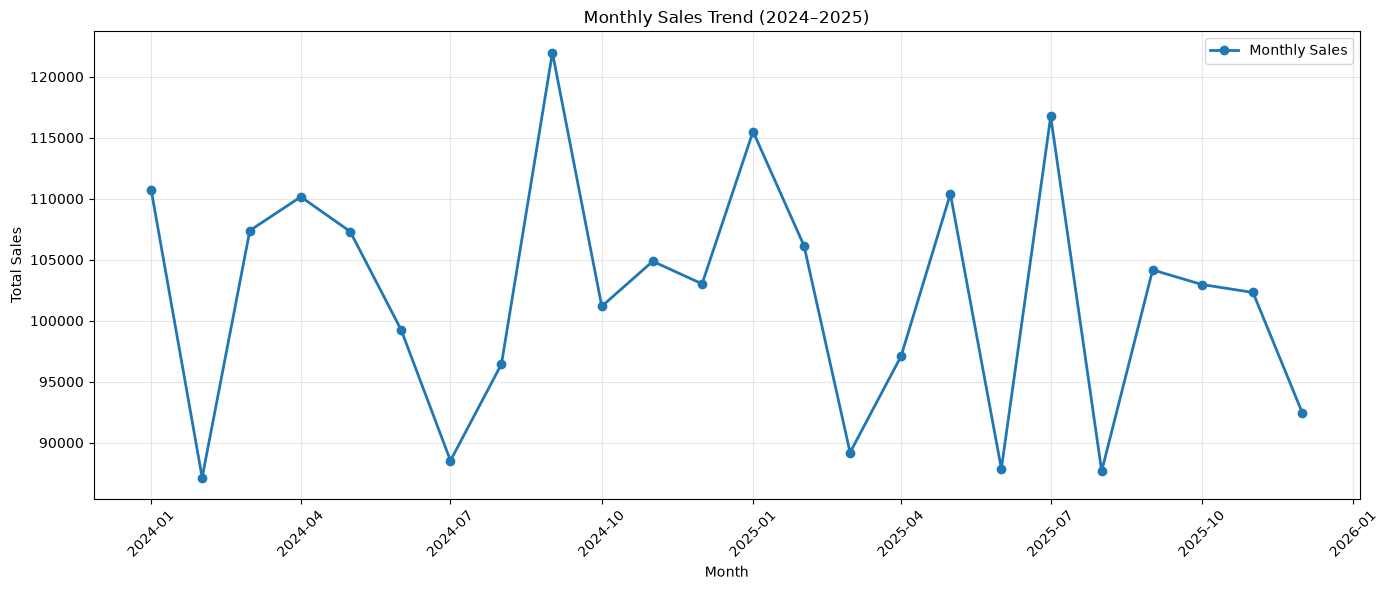

In [58]:
# Convert Year_Month into datetime
monthly_sales["Year_Month"] = pd.to_datetime(
    monthly_sales["Year_Month"]
)

# Create the figure
plt.figure(figsize=(14, 6))

# Plot monthly sales
plt.plot(
    monthly_sales["Year_Month"],
    monthly_sales["Total_Sales"],
    marker="o",
    linewidth=2,
    label="Monthly Sales"
)

# Add chart title and labels
plt.title("Monthly Sales Trend (2024–2025)")
plt.xlabel("Month")
plt.ylabel("Total Sales")

# Add grid and legend
plt.grid(True, alpha=0.3)
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

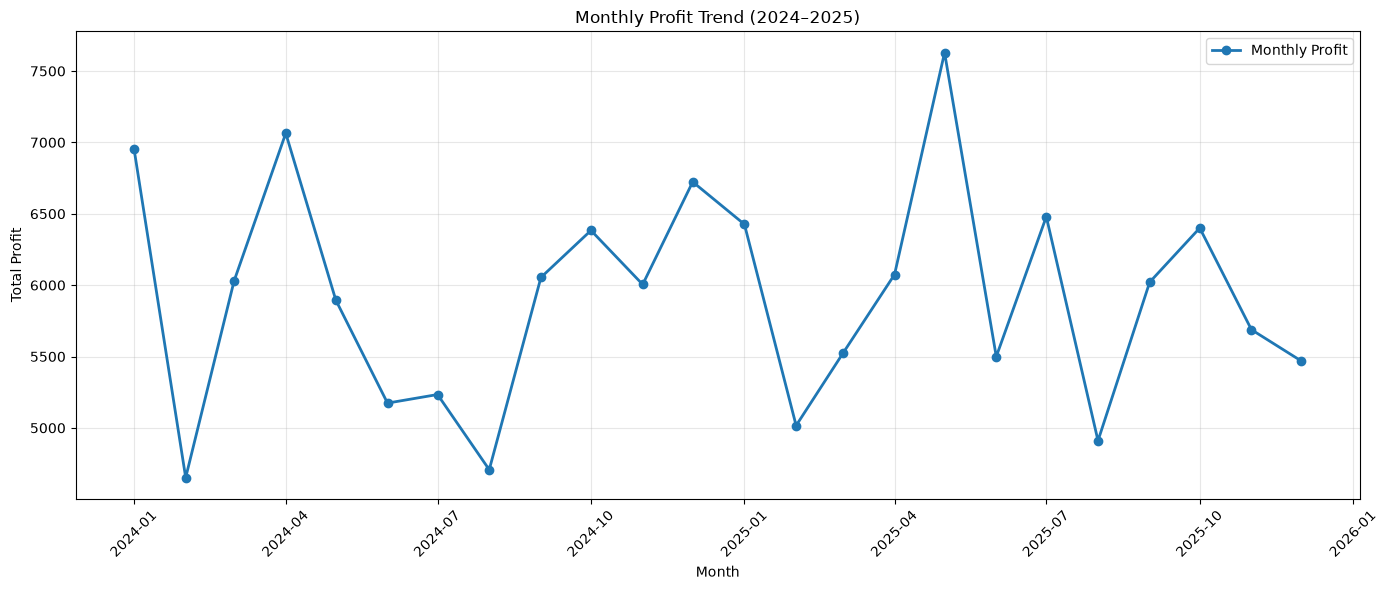

In [61]:
# Convert Year_Month into datetime
monthly_sales["Year_Month"] = pd.to_datetime(
    monthly_sales["Year_Month"]
)

# Create the figure
plt.figure(figsize=(14, 6))

# Plot monthly Profit
plt.plot(
    monthly_sales["Year_Month"],
    monthly_sales["Total_Profit"],
    marker="o",
    linewidth=2,
    label="Monthly Profit"
)

# Add chart title and labels
plt.title("Monthly Profit Trend (2024–2025)")
plt.xlabel("Month")
plt.ylabel("Total Profit")

# Add grid and legend
plt.grid(True, alpha=0.3)
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [64]:
print("Unique discount values:")
print(sorted(df_analysis["Discount"].unique()))

print("\nDiscount distribution:")
print(df_analysis["Discount"].value_counts().sort_index())

Unique discount values:
[np.float64(0.0), np.float64(0.05), np.float64(0.1), np.float64(0.15), np.float64(0.2), np.float64(0.3)]

Discount distribution:
Discount
0.00    821
0.05    833
0.10    821
0.15    808
0.20    834
0.30    864
Name: count, dtype: int64


In [65]:

bins = [-0.001, 0, 0.10, 0.20, float("inf")]

labels = [
    "No Discount",
    "Low Discount",
    "Medium Discount",
    "High Discount"
]

df_analysis["Discount_Group"] = pd.cut(
    df_analysis["Discount"],
    bins=bins,
    labels=labels
)

In [67]:
discount_analysis = (
    df_analysis.groupby("Discount_Group", observed=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order_ID", "nunique"),
        Average_Discount=("Discount", "mean")
    )
    .reset_index()
)

discount_analysis["Profit_Margin"] = (
    discount_analysis["Total_Profit"] /
    discount_analysis["Total_Sales"] * 100
)

print(discount_analysis.round(2).to_string(index=False))

 Discount_Group  Total_Sales  Total_Profit  Total_Orders  Average_Discount  Profit_Margin
    No Discount    407044.45      58504.24           722              0.00          14.37
   Low Discount    800388.52      75936.83          1277              0.07           9.49
Medium Discount    811849.98      27253.21          1248              0.18           3.36
  High Discount    431216.25     -19682.95           750              0.30          -4.56


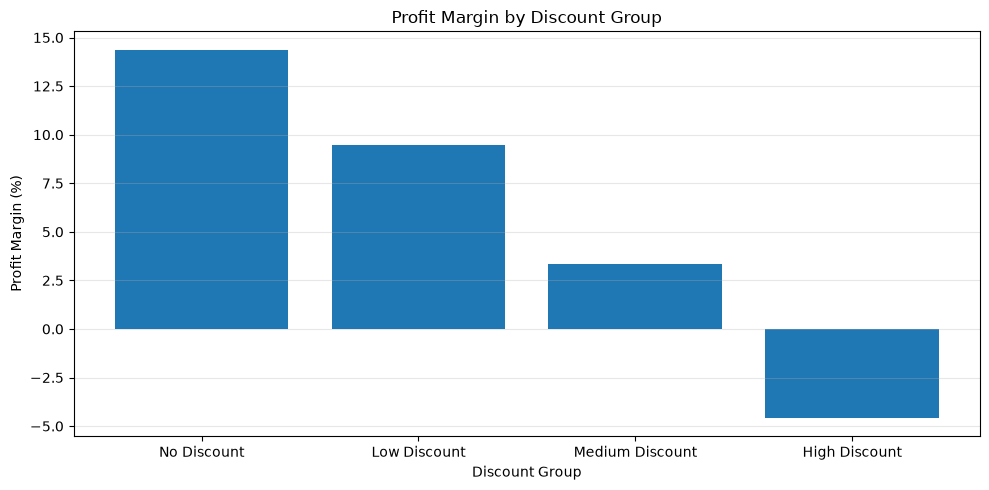

In [69]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    discount_analysis["Discount_Group"].astype(str),
    discount_analysis["Profit_Margin"]
)

plt.title("Profit Margin by Discount Group")
plt.xlabel("Discount Group")
plt.ylabel("Profit Margin (%)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

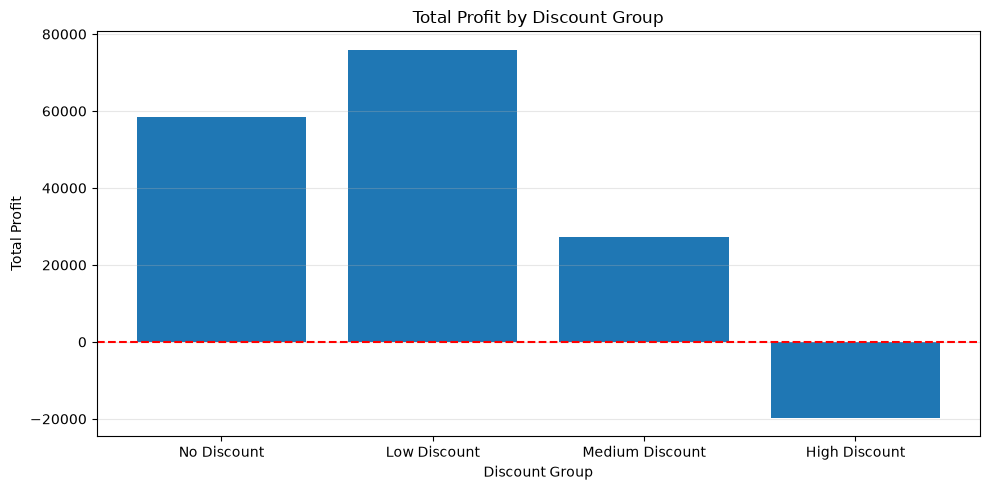

In [70]:
plt.figure(figsize=(10, 5))

plt.bar(
    discount_analysis["Discount_Group"].astype(str),
    discount_analysis["Total_Profit"]
)

plt.axhline(y=0, color="red", linestyle="--")

plt.title("Total Profit by Discount Group")
plt.xlabel("Discount Group")
plt.ylabel("Total Profit")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

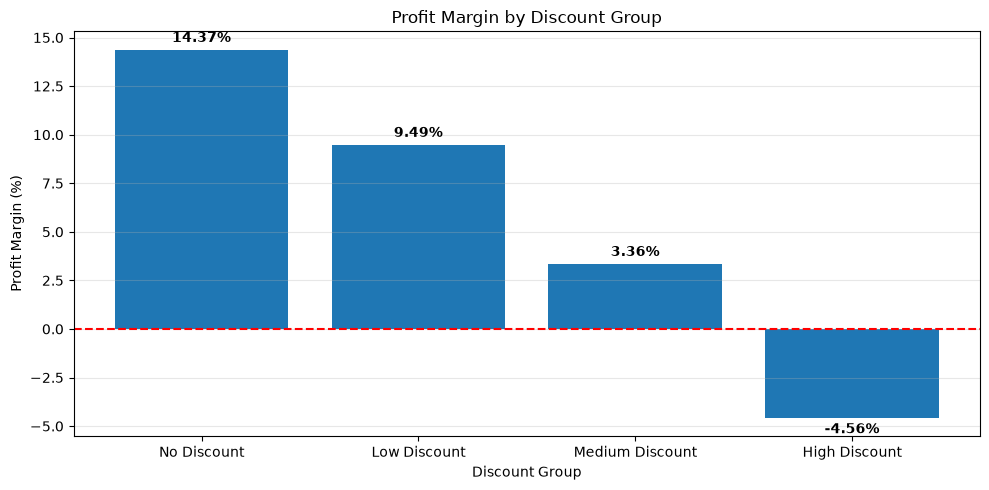

In [73]:
plt.figure(figsize=(10, 5))

plt.bar(
    discount_analysis["Discount_Group"].astype(str),
    discount_analysis["Profit_Margin"]
)

plt.axhline(y=0, color="red", linestyle="--")

plt.title("Profit Margin by Discount Group")
plt.xlabel("Discount Group")
plt.ylabel("Profit Margin (%)")
plt.grid(axis="y", alpha=0.3)
for i, value in enumerate(discount_analysis["Profit_Margin"]):
    plt.text(
        i,
        value + (0.4 if value >= 0 else -0.8),
        f"{value:.2f}%",
        ha="center",
        fontweight="bold"
    )
plt.tight_layout()
plt.show()


In [74]:
df_analysis = df_analysis.copy()

df_analysis["Shipping_Days"] = (
    df_analysis["Ship_Date"] - df_analysis["Order_Date"]
).dt.days

print(df_analysis[[
    "Order_ID",
    "Ship_Mode",
    "Order_Date",
    "Ship_Date",
    "Shipping_Days"
]].head(10))

    Order_ID       Ship_Mode Order_Date  Ship_Date  Shipping_Days
0  ORD-12233  Standard Class 2024-04-14 2024-04-20              6
1  ORD-12932        Same Day 2024-01-28 2024-02-02              5
2  ORD-10881     First Class 2024-12-14 2024-12-17              3
3  ORD-12196  Standard Class 2024-02-14 2024-02-20              6
4  ORD-12708    Second Class 2025-12-22 2025-12-23              1
5  ORD-10858     First Class 2024-06-15 2024-06-18              3
6  ORD-11105    Second Class 2024-06-16 2024-06-20              4
7  ORD-12940     First Class 2024-03-08 2024-03-10              2
8  ORD-12299     First Class 2024-09-28 2024-09-30              2
9  ORD-10449    Second Class 2025-05-20 2025-05-21              1


In [75]:
print("Shipping Methods:")
print(df_analysis["Ship_Mode"].value_counts())

print("\nShipping Days Summary:")
print(df_analysis["Shipping_Days"].describe())

print("\nShipping Days by Method:")
print(
    df_analysis.groupby("Ship_Mode")["Shipping_Days"]
    .agg(["mean", "median", "min", "max", "count"])
    .round(2)
)

Shipping Methods:
Ship_Mode
Same Day          1297
Standard Class    1252
First Class       1203
Second Class      1189
Unknown             40
Name: count, dtype: int64

Shipping Days Summary:
count    4981.000000
mean        4.006023
std         2.015593
min         1.000000
25%         2.000000
50%         4.000000
75%         6.000000
max         7.000000
Name: Shipping_Days, dtype: float64

Shipping Days by Method:
                mean  median  min  max  count
Ship_Mode                                    
First Class     4.00     4.0    1    7   1203
Same Day        4.04     4.0    1    7   1297
Second Class    3.94     4.0    1    7   1189
Standard Class  4.02     4.0    1    7   1252
Unknown         4.72     5.0    1    7     40


In [76]:
same_day_check = df_analysis[
    df_analysis["Ship_Mode"] == "Same Day"
]

print(
    same_day_check["Shipping_Days"]
    .value_counts()
    .sort_index()
)

print(
    same_day_check[
        ["Order_Date", "Ship_Date", "Shipping_Days"]
    ].head(15)
)

Shipping_Days
1    170
2    188
3    200
4    171
5    190
6    181
7    197
Name: count, dtype: int64
   Order_Date  Ship_Date  Shipping_Days
1  2024-01-28 2024-02-02              5
17 2025-06-10 2025-06-12              2
20 2024-05-23 2024-05-27              4
22 2025-01-23 2025-01-24              1
25 2025-08-31 2025-09-01              1
31 2024-06-14 2024-06-20              6
34 2025-02-26 2025-02-27              1
40 2024-11-12 2024-11-18              6
41 2024-06-27 2024-07-02              5
42 2025-11-01 2025-11-04              3
44 2024-09-07 2024-09-11              4
49 2025-02-28 2025-03-04              4
51 2024-08-13 2024-08-17              4
59 2025-05-16 2025-05-17              1
60 2025-07-05 2025-07-12              7


In [79]:
shipping_analysis = (
    df_analysis.groupby("Ship_Mode")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order_ID", "nunique"),
        Average_Shipping_Days=("Shipping_Days", "mean")
    )
    .reset_index()
)

shipping_analysis["Profit_Margin"] = (
    shipping_analysis["Total_Profit"] /
    shipping_analysis["Total_Sales"] * 100
)

print(shipping_analysis.round(2).to_string(index = False))

     Ship_Mode  Total_Sales  Total_Profit  Total_Orders  Average_Shipping_Days  Profit_Margin
   First Class    575292.99      34695.86           996                   4.00           6.03
      Same Day    614573.42      35617.22          1052                   4.04           5.80
  Second Class    610775.83      33216.02           979                   3.94           5.44
Standard Class    633889.40      37545.47          1039                   4.02           5.92
       Unknown     15967.56        936.76            40                   4.72           5.87


In [80]:
order_shipping_check = (
    df_analysis.groupby("Order_ID")["Ship_Mode"]
    .nunique()
)

print("Orders with multiple shipping methods:",
      (order_shipping_check > 1).sum())

Orders with multiple shipping methods: 1250


In [81]:
print(
    df_analysis[
        df_analysis["Ship_Mode"] == "Same Day"
    ]["Shipping_Days"].value_counts().sort_index()
)

Shipping_Days
1    170
2    188
3    200
4    171
5    190
6    181
7    197
Name: count, dtype: int64


In [82]:
order_shipping_details = (
    df_analysis.groupby("Order_ID")
    .agg(
        Shipping_Methods=("Ship_Mode", "nunique"),
        Shipping_Method_List=(
            "Ship_Mode",
            lambda x: ", ".join(sorted(x.unique()))
        ),
        Total_Items=("Product_ID", "count")
    )
    .reset_index()
)

multiple_shipping_orders = order_shipping_details[
    order_shipping_details["Shipping_Methods"] > 1
]

print(multiple_shipping_orders.head(15))

     Order_ID  Shipping_Methods  \
0   ORD-10000                 2   
1   ORD-10001                 2   
3   ORD-10003                 4   
4   ORD-10004                 2   
8   ORD-10008                 2   
10  ORD-10010                 3   
11  ORD-10011                 3   
13  ORD-10014                 2   
14  ORD-10015                 2   
17  ORD-10019                 3   
19  ORD-10021                 3   
21  ORD-10024                 2   
22  ORD-10026                 2   
26  ORD-10030                 2   
27  ORD-10032                 2   

                                 Shipping_Method_List  Total_Items  
0                           First Class, Second Class            2  
1                               First Class, Same Day            3  
3   First Class, Same Day, Second Class, Standard ...            4  
4                            Same Day, Standard Class            3  
8                              Same Day, Second Class            3  
10                First C

In [83]:
print(
    df_analysis.groupby("Order_ID")["Ship_Mode"]
    .nunique()
    .value_counts()
    .sort_index()
)

Ship_Mode
1    1187
2     879
3     324
4      46
5       1
Name: count, dtype: int64


In [84]:
order_validation = (
    df_analysis.groupby("Order_ID")
    .agg(
        Ship_Mode_Count=("Ship_Mode", "nunique"),
        Ship_Date_Count=("Ship_Date", "nunique"),
        Order_Date_Count=("Order_Date", "nunique"),
        Item_Count=("Product_ID", "count")
    )
    .reset_index()
)

print(order_validation[
    (order_validation["Ship_Mode_Count"] > 1) |
    (order_validation["Ship_Date_Count"] > 1) |
    (order_validation["Order_Date_Count"] > 1)
].head(20))

     Order_ID  Ship_Mode_Count  Ship_Date_Count  Order_Date_Count  Item_Count
0   ORD-10000                2                2                 2           2
1   ORD-10001                2                3                 3           3
3   ORD-10003                4                4                 4           4
4   ORD-10004                2                3                 3           3
8   ORD-10008                2                3                 3           3
10  ORD-10010                3                6                 6           6
11  ORD-10011                3                5                 5           5
13  ORD-10014                2                2                 2           2
14  ORD-10015                2                3                 3           3
15  ORD-10017                1                2                 2           2
17  ORD-10019                3                4                 4           4
19  ORD-10021                3                4                 

In [85]:
valid_orders = order_validation[
    (order_validation["Ship_Mode_Count"] == 1) &
    (order_validation["Ship_Date_Count"] == 1) &
    (order_validation["Order_Date_Count"] == 1)
]

print("Total Orders:", len(order_validation))
print("Valid Orders:", len(valid_orders))
print("Invalid Orders:", len(order_validation) - len(valid_orders))

print("\nValid Order Percentage:")
print(round(len(valid_orders) / len(order_validation) * 100, 2), "%")

Total Orders: 2437
Valid Orders: 967
Invalid Orders: 1470

Valid Order Percentage:
39.68 %


In [86]:
valid_order_ids = valid_orders["Order_ID"]

df_shipping = df_analysis[
    df_analysis["Order_ID"].isin(valid_order_ids)
].copy()

print("Shipping analysis shape:", df_shipping.shape)

print(
    df_shipping.groupby("Ship_Mode")
    .agg(
        Total_Orders=("Order_ID", "nunique"),
        Average_Shipping_Days=("Shipping_Days", "mean"),
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    ).round(2)
)

Shipping analysis shape: (967, 27)
                Total_Orders  Average_Shipping_Days  Total_Sales  Total_Profit
Ship_Mode                                                                     
First Class              235                   4.07    105211.61       6522.61
Same Day                 248                   3.99    111483.14       7205.16
Second Class             227                   4.08    116460.91       6252.88
Standard Class           252                   4.08    124043.07       7644.23
Unknown                    5                   5.20       612.05         27.61


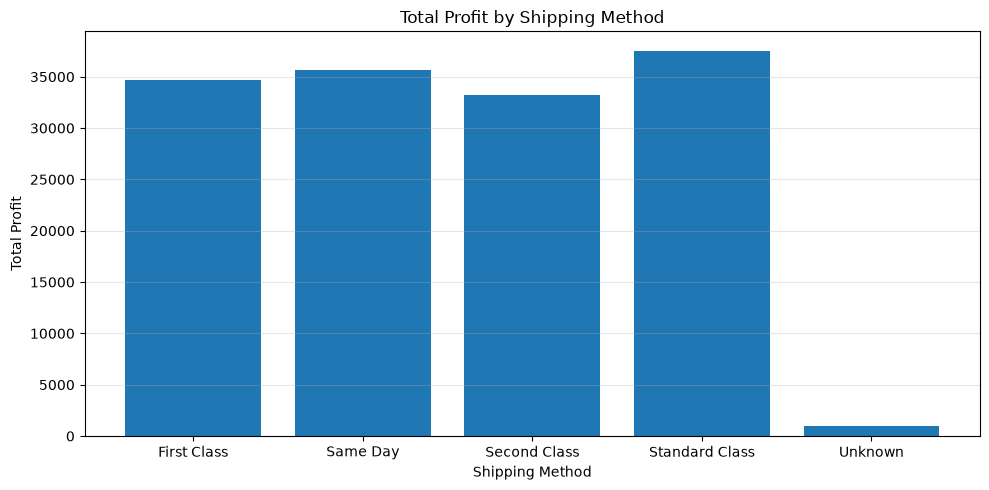

In [87]:
plt.figure(figsize=(10, 5))

plt.bar(
    shipping_analysis["Ship_Mode"].astype(str),
    shipping_analysis["Total_Profit"]
)

plt.title("Total Profit by Shipping Method")
plt.xlabel("Shipping Method")
plt.ylabel("Total Profit")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [88]:
shipping_valid_summary = (
    df_shipping.groupby("Ship_Mode")
    .agg(
        Total_Profit=("Profit", "sum"),
        Average_Shipping_Days=("Shipping_Days", "mean")
    )
    .reset_index()
)

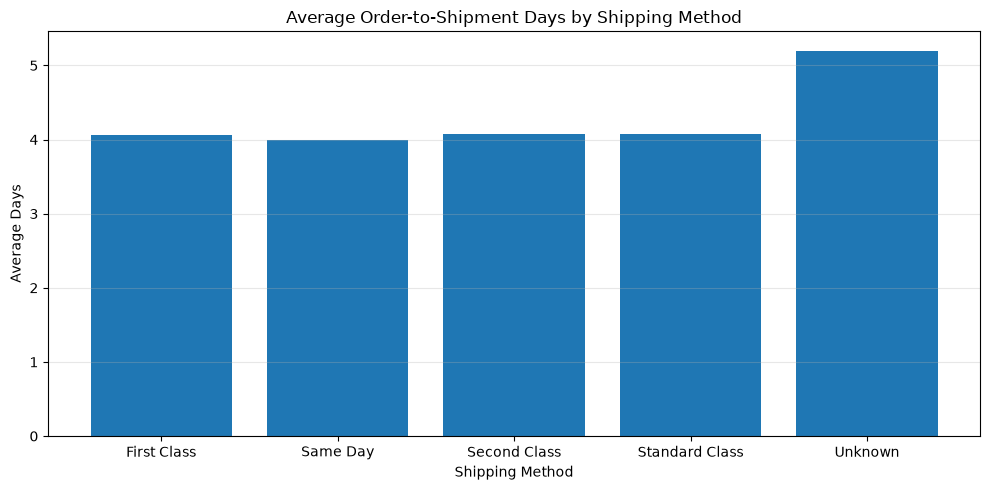

In [89]:
plt.figure(figsize=(10, 5))

plt.bar(
    shipping_valid_summary["Ship_Mode"].astype(str),
    shipping_valid_summary["Average_Shipping_Days"]
)

plt.title("Average Order-to-Shipment Days by Shipping Method")
plt.xlabel("Shipping Method")
plt.ylabel("Average Days")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [90]:
# Create a copy for Power BI
df_powerbi = df_analysis.copy()

# Identify orders with consistent shipping information
valid_order_ids = valid_orders["Order_ID"]

df_powerbi["Shipping_Order_Valid"] = (
    df_powerbi["Order_ID"].isin(valid_order_ids)
)

# Export the dataset
df_powerbi.to_csv(
    "ecommerce_sales_powerbi.csv",
    index=False
)

print("Power BI dataset exported successfully!")
print("Dataset shape:", df_powerbi.shape)

Power BI dataset exported successfully!
Dataset shape: (4981, 28)
